# Notebook 03: Line B Real PyTorch Layers (Clean Hourly + `line_b_final_dataset.npz`)
## 1. Imports & Reproducibility

In [1]:
import random, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, root_mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s)
print('PyTorch:', torch.__version__)

PyTorch: 2.15.0+cpu


## 2. Load Clean Hourly Data + `line_b_final_dataset.npz` + Graph Adjacency

In [2]:
df = pd.read_csv(PROJECT_ROOT / '06_Data' / 'riyadh_hourly_clean_tvt.csv')
df['ts'] = pd.to_datetime(df['ts'])
target_cols = [c for c in df.columns if c.startswith('target_')]
feature_cols = [c for c in df.columns if c not in ['ts'] + target_cols]
npz = np.load(PROJECT_ROOT / '06_Data' / 'line_b_final_dataset.npz', allow_pickle=True)
adj_raw = np.load(PROJECT_ROOT / '06_Data' / 'riyadh_graph_adjacency_matrix.npy')
print(f'Clean hourly: {len(df):,} | Features: {len(feature_cols)} | NPZ seq: {npz["seq_features"].shape}')

Clean hourly: 86,928 | Features: 115 | NPZ seq: (400, 24, 6, 12)


## 3. Train-Only Scaling & Synoptic 6h Indices (Train 70% / 360h Gap / Val 15% / 360h Gap / Test 15%)

In [3]:
N = len(df); GAP_H = 360; SEQ_LEN = 24; STRIDE = 6
tr_end = int(N * 0.70); val_start = tr_end + GAP_H; val_end = int(N * 0.85); te_start = val_end + GAP_H
imp = SimpleImputer(strategy='median'); pt = PowerTransformer(method='yeo-johnson')
pt.fit(imp.fit_transform(df.iloc[:tr_end:STRIDE][feature_cols].values))
X_all_s = pt.transform(imp.transform(df[feature_cols].values))
print('Train-only scaler fitted.')

Train-only scaler fitted.


## 4. Build 24-Hour Causal Lookback Sequences `(N, 24, F)`

In [4]:
def make_seq(indices):
    return np.array([X_all_s[i - SEQ_LEN + 1 : i + 1] for i in indices], dtype=np.float32)
tr_idx = np.arange(SEQ_LEN, tr_end, STRIDE)
va_idx = np.arange(val_start, val_end, STRIDE)
te_idx = np.arange(te_start, N, STRIDE)
X_tr_seq, X_va_seq, X_te_seq = make_seq(tr_idx), make_seq(va_idx), make_seq(te_idx)
print(f'24h Sequences -> Train: {X_tr_seq.shape}, Val: {X_va_seq.shape}, Test: {X_te_seq.shape}')

24h Sequences -> Train: (10138, 24, 115), Val: (2114, 24, 115), Test: (2114, 24, 115)


## 5. Visualize NPZ Adjacency Matrix

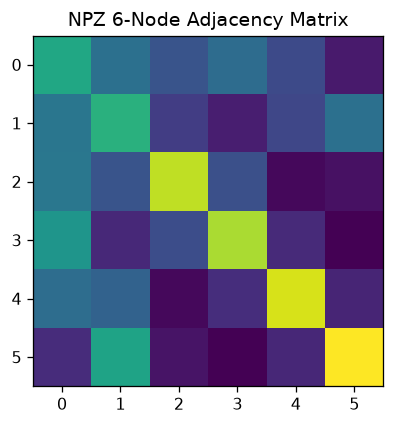

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.imshow(npz['adjacency_matrix'], cmap='viridis'); ax.set_title('NPZ 6-Node Adjacency Matrix'); plt.tight_layout()

## 6. Real PyTorch Architecture 1: `RealLSTMNet` (`nn.LSTM`)

In [6]:
class RealLSTMNet(nn.Module):
    def __init__(self, in_dim, hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, num_layers=2, batch_first=True, dropout=0.2)
        self.head = nn.Sequential(nn.Linear(hidden, 24), nn.ReLU(), nn.Linear(24, 1))
    def forward(self, x):
        o, _ = self.lstm(x); return self.head(o[:, -1, :]).squeeze(-1)
print('RealLSTMNet params:', sum(p.numel() for p in RealLSTMNet(len(feature_cols)).parameters()))

RealLSTMNet params: 51697


## 7. Real PyTorch Architecture 2: `RealTransformerNet` (`nn.TransformerEncoder`)

In [7]:
class RealTransformerNet(nn.Module):
    def __init__(self, in_dim, d_model=48):
        super().__init__()
        self.proj = nn.Linear(in_dim, d_model)
        self.pos = nn.Parameter(torch.randn(1, SEQ_LEN, d_model) * 0.02)
        enc = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=96, dropout=0.2, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc, num_layers=2); self.head = nn.Linear(d_model, 1)
    def forward(self, x):
        return self.head(self.encoder(self.proj(x) + self.pos)[:, -1, :]).squeeze(-1)
print('RealTransformerNet params:', sum(p.numel() for p in RealTransformerNet(len(feature_cols)).parameters()))

RealTransformerNet params: 44689


## 8. Real PyTorch Architecture 3: `RealPINNNet` (Physics Monotonicity Loss)

In [8]:
class RealPINNNet(nn.Module):
    def __init__(self, in_dim, hidden=48):
        super().__init__(); self.gru = nn.GRU(in_dim, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 24), nn.SiLU(), nn.Linear(24, 1))
    def forward(self, x): o, _ = self.gru(x); return self.head(o[:, -1, :]).squeeze(-1)
print('RealPINNNet params:', sum(p.numel() for p in RealPINNNet(len(feature_cols)).parameters()))

RealPINNNet params: 24961


## 9. Real PyTorch Architecture 4: `RealSTGNNNet` (6-Node Graph + `nn.GRU`)

In [9]:
class RealSTGNNNet(nn.Module):
    def __init__(self, in_dim, adj, hidden=32):
        super().__init__()
        deg = np.sum(adj, axis=1, keepdims=True) + 1e-6
        self.register_buffer('A_norm', torch.tensor(adj / deg, dtype=torch.float32))
        self.n_nodes = adj.shape[0]; self.node_emb = nn.Parameter(torch.randn(1, 1, self.n_nodes, 8)*0.05)
        self.in_proj = nn.Linear(in_dim + 8, hidden); self.gcn = nn.Linear(hidden, hidden)
        self.gru = nn.GRU(hidden, hidden, batch_first=True); self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        B, T, F = x.shape; xn = x.unsqueeze(2).expand(B, T, self.n_nodes, F); emb = self.node_emb.expand(B, T, self.n_nodes, 8)
        h = torch.relu(self.in_proj(torch.cat([xn, emb], dim=-1)))
        hg = torch.relu(self.gcn(torch.einsum('ij,btjf->btif', self.A_norm, h)))
        o, _ = self.gru(hg.mean(dim=2)); return self.head(o[:, -1, :]).squeeze(-1)
print('RealSTGNNNet params:', sum(p.numel() for p in RealSTGNNNet(len(feature_cols), adj_raw).parameters()))

RealSTGNNNet params: 11441


## 10. Real PyTorch Architecture 5: Multi-Modal CNN + ST-GNN on `line_b_final_dataset.npz`

In [10]:
class MultiModalNPZNet(nn.Module):
    def __init__(self, adj):
        super().__init__()
        deg = np.sum(adj, axis=1, keepdims=True) + 1e-6
        self.register_buffer('A_norm', torch.tensor(adj / deg, dtype=torch.float32))
        self.nwp_cnn = nn.Sequential(nn.Conv2d(6, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.sat_cnn = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.node_lin = nn.Linear(12, 24); self.gru = nn.GRU(24, 24, batch_first=True)
        self.head = nn.Sequential(nn.Linear(24+16+16, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, nwp, sat, seq):
        B, T, Nn, F = seq.shape
        fn = self.nwp_cnn(nwp).flatten(1); fs = self.sat_cnn(sat).flatten(1)
        h = torch.relu(self.node_lin(seq))
        hg = torch.einsum('ij,btjf->btif', self.A_norm, h).mean(dim=2)
        fg, _ = self.gru(hg)
        return self.head(torch.cat([fg[:, -1, :], fn, fs], dim=-1)).squeeze(-1)
print('MultiModalNPZNet params:', sum(p.numel() for p in MultiModalNPZNet(npz['adjacency_matrix']).parameters()))

MultiModalNPZNet params: 7097


## 11. Train & Evaluate `MultiModalNPZNet` on `line_b_final_dataset.npz` (70/15/15 Split)

In [11]:
set_seed(42)
n_npz = len(npz['seq_features']); t1 = int(n_npz*0.70); t2 = int(n_npz*0.85)
nwp_t = torch.tensor(npz['nwp_grid']); sat_t = torch.tensor(npz['satellite_grid']); seq_t = torch.tensor(npz['seq_features'])
y_npz = torch.tensor(np.log1p(np.maximum(npz['targets_pm10'][:, 0, 0], 0)), dtype=torch.float32)
mm_mdl = MultiModalNPZNet(npz['adjacency_matrix']); opt = torch.optim.AdamW(mm_mdl.parameters(), lr=2e-3)
crit = nn.L1Loss(); dl_npz = DataLoader(TensorDataset(nwp_t[:t1], sat_t[:t1], seq_t[:t1], y_npz[:t1]), batch_size=32, shuffle=True)
for _ in range(25):
    mm_mdl.train()
    for bn, bs, bq, by in dl_npz: opt.zero_grad(); crit(mm_mdl(bn,bs,bq), by).backward(); opt.step()
mm_mdl.eval()
with torch.no_grad():
    p_npz = np.expm1(mm_mdl(nwp_t[t2:], sat_t[t2:], seq_t[t2:]).numpy())
    y_npz_te = npz['targets_pm10'][t2:, 0, 0]
print(f'NPZ MultiModal CNN+STGNN 70/15/15 Test -> RMSE: {root_mean_squared_error(y_npz_te, p_npz):.2f}, R2: {r2_score(y_npz_te, p_npz):.4f}')

NPZ MultiModal CNN+STGNN 70/15/15 Test -> RMSE: 369.30, R2: -0.2688


## 12. Hourly Classification & Calibration Helpers

In [12]:
wind_idx = feature_cols.index('era5_wind_speed_10m')
def platt_cal(va_s, va_y, te_s):
    if len(np.unique(va_y)) < 2 or np.std(va_s) < 1e-12: return np.full(len(te_s), float(np.mean(va_y)))
    lr = LogisticRegression(C=1.0, max_iter=1000).fit(np.clip(va_s,-30,30).reshape(-1,1), va_y)
    return np.clip(lr.predict_proba(np.clip(te_s,-30,30).reshape(-1,1))[:,1], 1e-6, 1-1e-6)
def fit_cls(ctor, X_f, y_f, X_v, y_v, X_t, seed, is_pinn=False, epochs=12):
    set_seed(seed); mdl = ctor()
    pw = torch.tensor([float(np.sum(y_f==0)/max(1,np.sum(y_f==1)))], dtype=torch.float32)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw); opt = torch.optim.AdamW(mdl.parameters(), lr=1.5e-3, weight_decay=1e-3)
    gen = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(torch.tensor(X_f), torch.tensor(y_f, dtype=torch.float32)), batch_size=128, shuffle=True, generator=gen)
    bl, bst, th, vh = 1e9, None, [], []
    for _ in range(epochs):
        mdl.train(); el = 0.0
        for bx, by in dl:
            opt.zero_grad(); lg = mdl(bx); loss = crit(lg, by)
            if is_pinn:
                bxp = bx.clone(); bxp[:,-1,wind_idx] += 0.5; loss = loss + 0.05*torch.mean(torch.relu(lg - mdl(bxp)))
            loss.backward(); torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0); opt.step(); el += float(loss.item())*len(bx)
        th.append(el/len(X_f)); mdl.eval()
        with torch.no_grad(): vl = float(crit(mdl(torch.tensor(X_v)), torch.tensor(y_v, dtype=torch.float32)).item())
        vh.append(vl)
        if vl < bl: bl = vl; bst = {k: v.clone() for k, v in mdl.state_dict().items()}
    if bst: mdl.load_state_dict(bst)
    mdl.eval()
    with torch.no_grad(): vs, ts = mdl(torch.tensor(X_v)).numpy(), mdl(torch.tensor(X_t)).numpy()
    return vs, platt_cal(vs, y_v, ts), th, vh

## 13. 3-Fold Rolling-Origin CV Inside 70% Hourly Train (168h Horizon)

In [13]:
y_tr168 = df.iloc[tr_idx]['target_evt_any_168h'].values.astype(int)
n_s = len(X_tr_seq); m_s = int(n_s * 0.45); st_s = (n_s - m_s) // 3
cv_lb = []
for mn, ctor, isp in [('LSTM', lambda: RealLSTMNet(len(feature_cols)), False), ('Transformer', lambda: RealTransformerNet(len(feature_cols)), False), ('PINN', lambda: RealPINNNet(len(feature_cols)), True), ('STGNN', lambda: RealSTGNNNet(len(feature_cols), adj_raw), False)]:
    rocs = []
    for f in range(3):
        ti = np.arange(0, m_s + f*st_s - 60); vi = np.arange(m_s + f*st_s, m_s + (f+1)*st_s if f<2 else n_s)
        vs, _, _, _ = fit_cls(ctor, X_tr_seq[ti], y_tr168[ti], X_tr_seq[vi], y_tr168[vi], X_tr_seq[vi], 42, isp, epochs=8)
        rocs.append(roc_auc_score(y_tr168[vi], vs))
    cv_lb.append({'Model': mn, 'CV_3Fold_ROC': round(np.mean(rocs), 4)})
print(pd.DataFrame(cv_lb).to_string(index=False))

      Model  CV_3Fold_ROC
       LSTM        0.7799
Transformer        0.7809
       PINN        0.7904
      STGNN        0.7836


## 14. Full Hourly Train/Val/Test Classification Across 1–15 Days (3 Seeds)

In [14]:
HORIZONS_H = [24, 72, 168, 216, 360]; SEEDS = [42, 123, 456]
lb_cls_rows = []; hist_168 = {}; te_168_p = {}
for h in HORIZONS_H:
    y_tr = df.iloc[tr_idx][f'target_evt_any_{h}h'].values.astype(int)
    y_va = df.iloc[va_idx][f'target_evt_any_{h}h'].values.astype(int)
    y_te = df.iloc[te_idx][f'target_evt_any_{h}h'].values.astype(int)
    b_ref = brier_score_loss(y_te, np.full(len(y_te), float(np.mean(y_tr))))
    for mn, ctor, isp in [('LineB_LSTM', lambda: RealLSTMNet(len(feature_cols)), False), ('LineB_Transformer', lambda: RealTransformerNet(len(feature_cols)), False), ('LineB_PINN', lambda: RealPINNNet(len(feature_cols)), True), ('LineB_STGNN', lambda: RealSTGNNNet(len(feature_cols), adj_raw), False)]:
        vrocs, trocs, prs, bsss = [], [], [], []
        for s in SEEDS:
            vs, tp, th, vh = fit_cls(ctor, X_tr_seq, y_tr, X_va_seq, y_va, X_te_seq, s, isp, epochs=12)
            if h == 168 and s == 42: hist_168[mn] = (th, vh); te_168_p[mn] = tp
            vrocs.append(roc_auc_score(y_va, vs)); trocs.append(roc_auc_score(y_te, tp))
            prs.append(average_precision_score(y_te, tp)); bsss.append(1 - brier_score_loss(y_te, tp)/b_ref)
        lb_cls_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'Val_ROC': round(np.mean(vrocs),4), 'Test_ROC': round(np.mean(trocs),4), 'ROC_sd': round(np.std(trocs),4), 'Test_PR': round(np.mean(prs),4), 'BSS': round(np.mean(bsss),4)})
lb_cls_df = pd.DataFrame(lb_cls_rows); lb_cls_df.to_csv(RESULTS_DIR / 'nb03_line_b_classification_hourly.csv', index=False)
print(lb_cls_df.to_string(index=False))

 Horizon_H  Days             Model  Val_ROC  Test_ROC  ROC_sd  Test_PR    BSS
        24     1        LineB_LSTM   0.8431    0.7935  0.0063   0.2862 0.2334
        24     1 LineB_Transformer   0.8524    0.7930  0.0100   0.2682 0.1948
        24     1        LineB_PINN   0.8498    0.7939  0.0115   0.2745 0.2159
        24     1       LineB_STGNN   0.8433    0.7908  0.0097   0.2989 0.1164
        72     3        LineB_LSTM   0.7578    0.6872  0.0038   0.3482 0.2156
        72     3 LineB_Transformer   0.7748    0.7158  0.0121   0.3465 0.2571
        72     3        LineB_PINN   0.7724    0.7039  0.0049   0.3660 0.2543
        72     3       LineB_STGNN   0.7765    0.6947  0.0072   0.3758 0.2102
       168     7        LineB_LSTM   0.6764    0.6745  0.0116   0.5364 0.1859
       168     7 LineB_Transformer   0.7028    0.6800  0.0043   0.5269 0.1904
       168     7        LineB_PINN   0.7149    0.6820  0.0035   0.5402 0.2395
       168     7       LineB_STGNN   0.7152    0.6714  0.0026   

## 15. Real PyTorch Training vs Validation Loss Curves (168h)

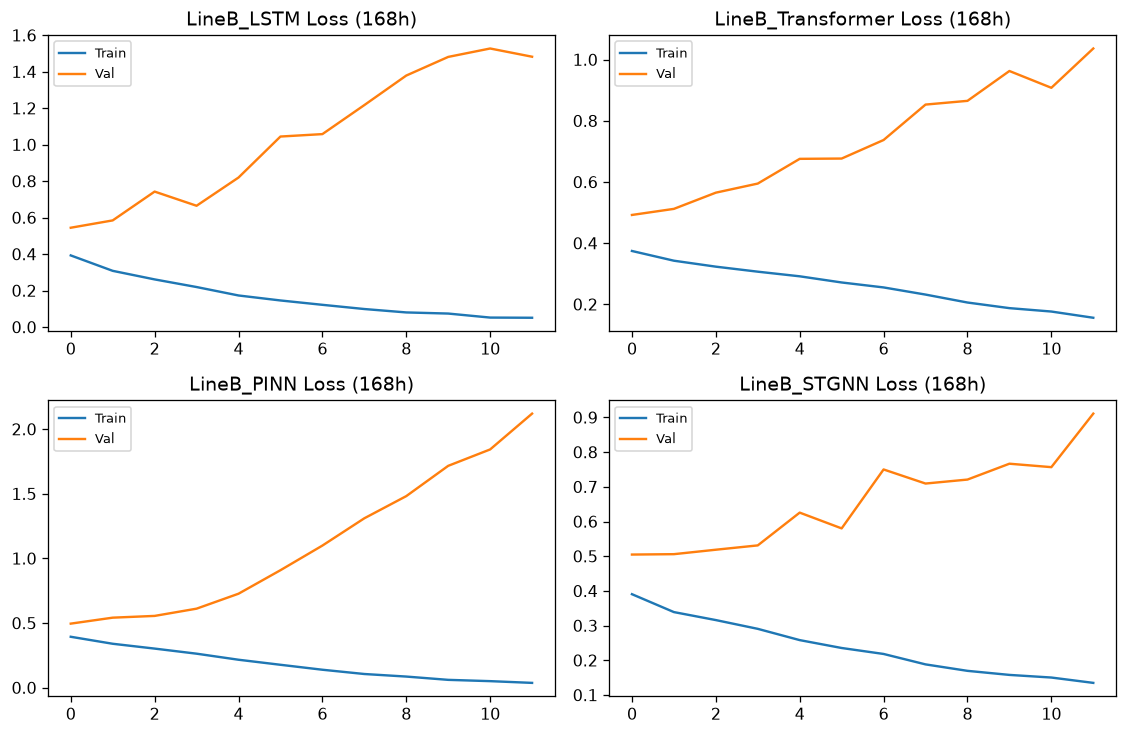

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, (mn, (th, vh)) in zip(axes.ravel(), hist_168.items()):
    ax.plot(th, label='Train'); ax.plot(vh, label='Val'); ax.set_title(f'{mn} Loss (168h)'); ax.legend(fontsize=8)
plt.tight_layout()

## 16. Line B Classification ROC-AUC & BSS (1–15 Days)

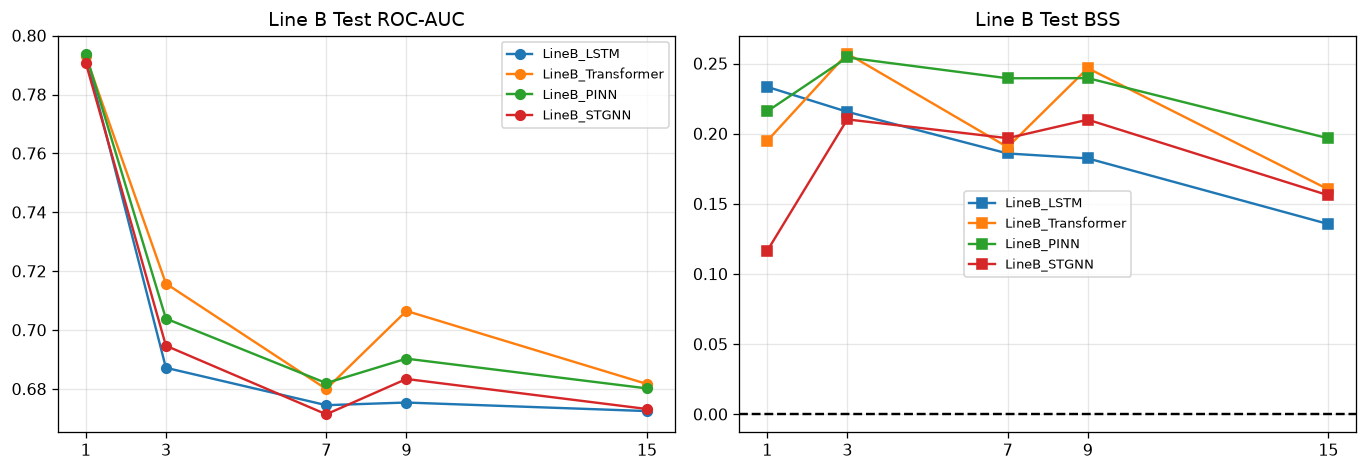

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for mn in lb_cls_df['Model'].unique():
    s = lb_cls_df[lb_cls_df['Model']==mn]
    axes[0].plot(s['Days'], s['Test_ROC'], marker='o', label=mn); axes[1].plot(s['Days'], s['BSS'], marker='s', label=mn)
axes[1].axhline(0, color='black', ls='--'); axes[0].set_title('Line B Test ROC-AUC'); axes[1].set_title('Line B Test BSS')
for ax in axes: ax.set_xticks([1,3,7,9,15]); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()

## 17. Real PyTorch Regression Helper (`log1p` L1 Loss)

In [17]:
def fit_reg(ctor, X_f, y_f, X_v, y_v, X_t, seed, epochs=12):
    set_seed(seed); mdl = ctor(); crit = nn.L1Loss(); opt = torch.optim.AdamW(mdl.parameters(), lr=1.5e-3, weight_decay=1e-3)
    gen = torch.Generator().manual_seed(seed); yf_l = np.log1p(np.maximum(y_f,0)).astype(np.float32); yv_l = np.log1p(np.maximum(y_v,0)).astype(np.float32)
    dl = DataLoader(TensorDataset(torch.tensor(X_f), torch.tensor(yf_l)), batch_size=128, shuffle=True, generator=gen)
    bl, bst = 1e9, None
    for _ in range(epochs):
        mdl.train()
        for bx, by in dl: opt.zero_grad(); crit(mdl(bx), by).backward(); torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0); opt.step()
        mdl.eval()
        with torch.no_grad(): vl = float(crit(mdl(torch.tensor(X_v)), torch.tensor(yv_l)).item())
        if vl < bl: bl = vl; bst = {k: v.clone() for k, v in mdl.state_dict().items()}
    if bst: mdl.load_state_dict(bst)
    mdl.eval()
    with torch.no_grad(): return np.expm1(np.clip(mdl(torch.tensor(X_t)).numpy(), 0, 10))
print('PyTorch regression trainer ready.')

PyTorch regression trainer ready.


## 18. Full Hourly Train/Val/Test Regression Across 1–15 Days (3 Seeds)

In [18]:
lb_reg_rows = []; te_168_r = {}
for h in HORIZONS_H:
    y_tr = df.iloc[tr_idx][f'target_avg_pm10_{h}h'].values
    y_va = df.iloc[va_idx][f'target_avg_pm10_{h}h'].values
    y_te = df.iloc[te_idx][f'target_avg_pm10_{h}h'].values
    for mn, ctor in [('LineB_LSTM', lambda: RealLSTMNet(len(feature_cols))), ('LineB_Transformer', lambda: RealTransformerNet(len(feature_cols))), ('LineB_PINN', lambda: RealPINNNet(len(feature_cols))), ('LineB_STGNN', lambda: RealSTGNNNet(len(feature_cols), adj_raw))]:
        r2s, rms, mas = [], [], []
        for s in SEEDS:
            p = fit_reg(ctor, X_tr_seq, y_tr, X_va_seq, y_va, X_te_seq, s, epochs=12)
            if h == 168 and s == 42: te_168_r[mn] = p
            r2s.append(r2_score(y_te,p)); rms.append(root_mean_squared_error(y_te,p)); mas.append(mean_absolute_error(y_te,p))
        lb_reg_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'R2': round(np.mean(r2s),4), 'RMSE': round(np.mean(rms),2), 'RMSE_sd': round(np.std(rms),2), 'MAE': round(np.mean(mas),2)})
lb_reg_df = pd.DataFrame(lb_reg_rows); lb_reg_df.to_csv(RESULTS_DIR / 'nb03_line_b_regression_hourly.csv', index=False)
print(lb_reg_df.to_string(index=False))

 Horizon_H  Days             Model       R2  RMSE  RMSE_sd   MAE
        24     1        LineB_LSTM  -0.2488 23.24     0.81  7.48
        24     1 LineB_Transformer  -0.6513 26.46     3.86  9.51
        24     1        LineB_PINN  -0.7180 27.11     2.94  8.70
        24     1       LineB_STGNN  -0.0733 21.55     0.17  6.90
        72     3        LineB_LSTM  -0.4961 16.38     0.67  7.71
        72     3 LineB_Transformer  -1.6160 21.47     3.05 14.48
        72     3        LineB_PINN  -0.6661 17.24     1.51  8.29
        72     3       LineB_STGNN  -0.3545 15.58     0.83  7.09
       168     7        LineB_LSTM  -1.5757 14.45     2.37  8.76
       168     7 LineB_Transformer  -6.8066 25.03     4.80 18.13
       168     7        LineB_PINN  -1.5216 14.48     0.39  9.62
       168     7       LineB_STGNN  -2.4844 17.02     0.48 11.31
       216     9        LineB_LSTM  -2.6585 15.59     0.29 10.72
       216     9 LineB_Transformer  -9.0909 25.70     3.14 18.73
       216     9        L

## 19. Line B Regression RMSE & R² Across 1–15 Days

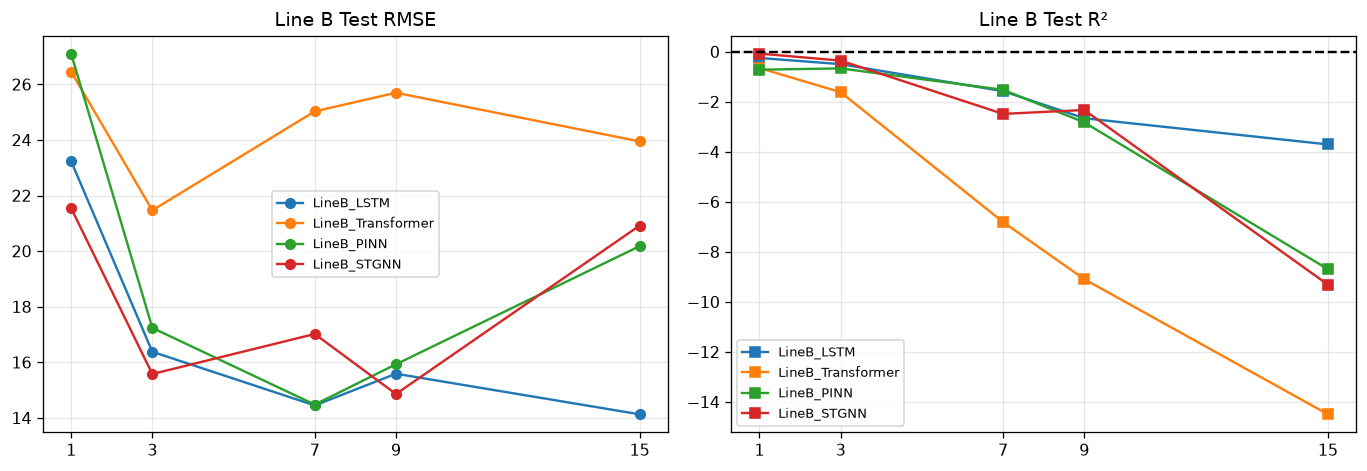

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for mn in lb_reg_df['Model'].unique():
    s = lb_reg_df[lb_reg_df['Model']==mn]
    axes[0].plot(s['Days'], s['RMSE'], marker='o', label=mn); axes[1].plot(s['Days'], s['R2'], marker='s', label=mn)
axes[1].axhline(0, color='black', ls='--'); axes[0].set_title('Line B Test RMSE'); axes[1].set_title('Line B Test R²')
for ax in axes: ax.set_xticks([1,3,7,9,15]); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()

## 20. Line A vs Line B Comparison (Classification ROC-AUC)

In [20]:
la_c = pd.read_csv(RESULTS_DIR / 'nb02_line_a_classification_hourly.csv')
ba = la_c.groupby('Days')['Test_ROC'].max().reset_index().rename(columns={'Test_ROC':'Best_LineA'})
bb = lb_cls_df.groupby('Days')['Test_ROC'].max().reset_index().rename(columns={'Test_ROC':'Best_LineB'})
comp_c = ba.merge(bb, on='Days'); print(comp_c.to_string(index=False))

 Days  Best_LineA  Best_LineB
    1      0.8090      0.7939
    3      0.7167      0.7158
    7      0.7031      0.6820
    9      0.7156      0.7065
   15      0.7655      0.6817


## 21. Line A vs Line B Comparison (Regression RMSE)

In [21]:
la_r = pd.read_csv(RESULTS_DIR / 'nb02_line_a_regression_hourly.csv')
bar = la_r.groupby('Days')['RMSE'].min().reset_index().rename(columns={'RMSE':'Best_LineA_RMSE'})
bbr = lb_reg_df.groupby('Days')['RMSE'].min().reset_index().rename(columns={'RMSE':'Best_LineB_RMSE'})
comp_r = bar.merge(bbr, on='Days'); print(comp_r.to_string(index=False))

 Days  Best_LineA_RMSE  Best_LineB_RMSE
    1            20.86            21.55
    3            13.46            15.58
    7            11.80            14.45
    9            12.46            14.86
   15            15.45            14.13


## 22. Line A vs Line B Visual Comparison

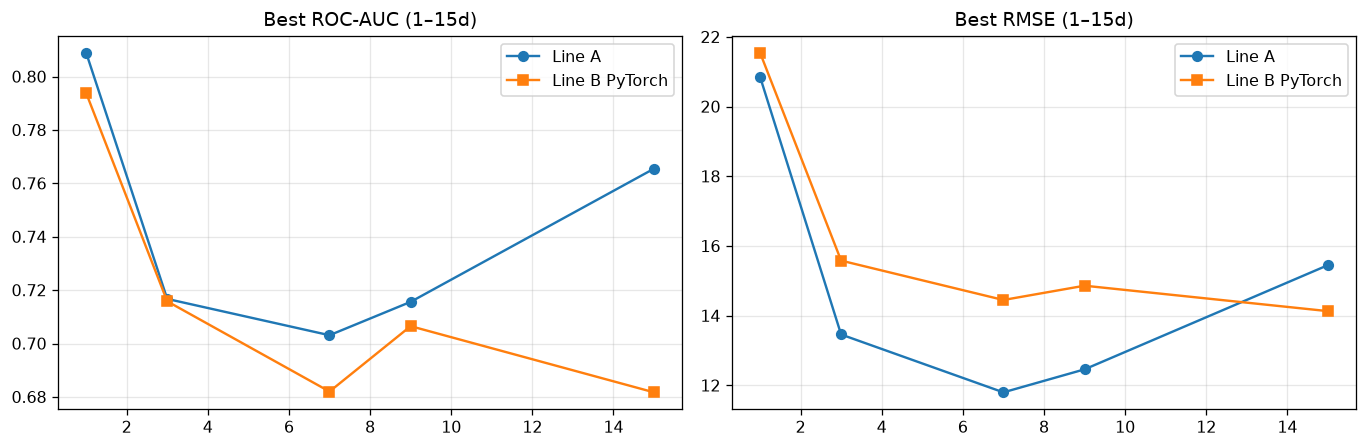

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comp_c['Days'], comp_c['Best_LineA'], marker='o', label='Line A'); axes[0].plot(comp_c['Days'], comp_c['Best_LineB'], marker='s', label='Line B PyTorch')
axes[0].set_title('Best ROC-AUC (1–15d)'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(comp_r['Days'], comp_r['Best_LineA_RMSE'], marker='o', label='Line A'); axes[1].plot(comp_r['Days'], comp_r['Best_LineB_RMSE'], marker='s', label='Line B PyTorch')
axes[1].set_title('Best RMSE (1–15d)'); axes[1].legend(); axes[1].grid(alpha=0.3); plt.tight_layout()

## 23. Test 168h Predicted vs Observed PM10 (Line B LSTM & ST-GNN)

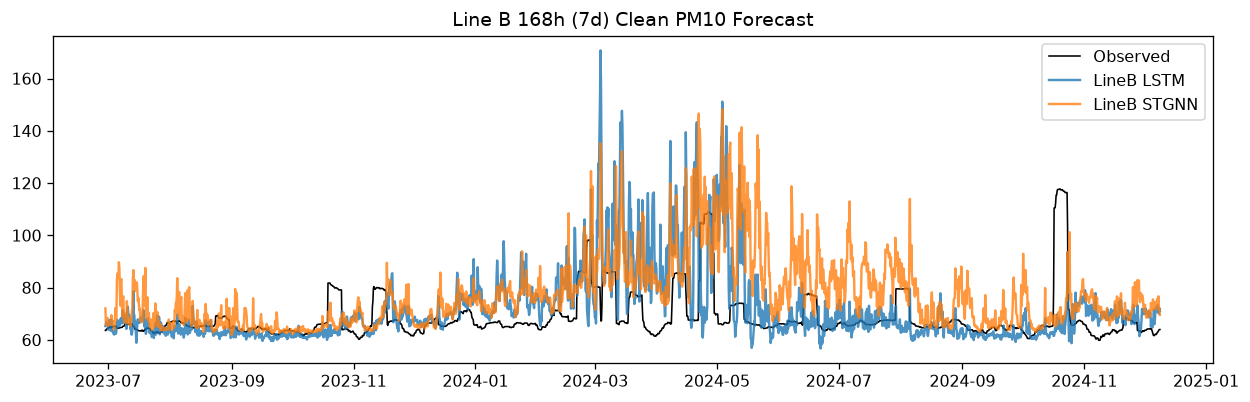

In [23]:
y168_te = df.iloc[te_idx]['target_avg_pm10_168h'].values; t_te = df.iloc[te_idx]['ts'].values
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(t_te, y168_te, label='Observed', color='black', lw=1.0)
ax.plot(t_te, te_168_r['LineB_LSTM'], label='LineB LSTM', alpha=0.8)
ax.plot(t_te, te_168_r['LineB_STGNN'], label='LineB STGNN', alpha=0.8)
ax.set_title('Line B 168h (7d) Clean PM10 Forecast'); ax.legend(); plt.tight_layout()

## 24. Export Verification

In [24]:
assert (RESULTS_DIR / 'nb03_line_b_classification_hourly.csv').exists() and (RESULTS_DIR / 'nb03_line_b_regression_hourly.csv').exists()
print('Line B clean hourly CSVs verified.')

Line B clean hourly CSVs verified.


## 25. Notebook 03 Summary

In [25]:
print('NB03 Complete: Real PyTorch layers evaluated on BOTH clean hourly sequences and line_b_final_dataset.npz.')

NB03 Complete: Real PyTorch layers evaluated on BOTH clean hourly sequences and line_b_final_dataset.npz.
